# 05 · PET Imaging — AV-133 (VMAT2) EDA
> *AV-133 is a PET tracer that labels dopamine storage vesicles — complementary to DaTSCAN but measuring a different aspect of the dopamine system.*

## Background: What is AV-133 PET?

**AV-133** (also called Florbetapir or ¹⁸F-Fluorodeoxyglucose... actually AV-133 = ¹⁸F-AV-133 / DTBZ analogue) is a radioactive tracer that binds to **VMAT2** — Vesicular Monoamine Transporter Type 2.

**VMAT2** is a protein that packages dopamine into storage vesicles inside the neuron.

**Comparison with DaTSCAN:**

| Property | DaTSCAN (DAT) | AV-133 (VMAT2) |
|----------|--------------|-----------------|
| What it labels | Dopamine **transporter** on cell surface | Dopamine **storage vesicles** inside cell |
| Sensitivity to PD | High | High |
| Affected by drugs | Yes (e.g., stimulants block DAT) | Less so |
| Available in PPMI | 10,000+ scans | ~257 scans |

**Key measurement — Striatal Binding Ratio (SBR):**
Same concept as DaTSCAN: (region uptake) / (reference region) − 1.

Regions measured:
- `PET_RCAUD_S` / `PET_LCAUD_S` = Right/Left Caudate SBR
- `PET_RPUTANT_S` / `PET_LPUTANT_S` = Right/Left Anterior Putamen SBR
- `PET_RPUTPOST_S` / `PET_LPUTPOST_S` = Right/Left Posterior Putamen SBR

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data Files

In [3]:
acq_meta = pd.read_csv(DATA_DIR / 'PET_Acquisition_Metadata_12Nov2026.csv')
sbr_pet  = pd.read_csv(DATA_DIR / 'PET_SBR_Analysis_12Nov2026.csv')
early    = pd.read_csv(DATA_DIR / 'Early_Imaging_Substudy_AV-133_PET_Imaging_12Nov2026.csv')
prodromal= pd.read_csv(DATA_DIR / 'AV-133_Prodromal_Imaging_Substudy_AV-133_PET_Imaging_12Nov2026.csv')
dual_pd  = pd.read_csv(DATA_DIR / 'Dual_PET_AV-133_in_PD_Imaging_Substudy_AV-133_PET_Imaging_12Nov2026.csv')
dual_pi  = pd.read_csv(DATA_DIR / 'Dual_PET_AV133_in_PI_Substudy_AV-133_NX_PET_Imaging_12Nov2026.csv')
for name, df in [('Acquisition Metadata', acq_meta), ('SBR Analysis', sbr_pet),
                 ('Early Imaging Substudy', early), ('Prodromal Substudy', prodromal),
                 ('Dual PET PD', dual_pd), ('Dual PET PI', dual_pi)]:
    print(f'{name:30s}: {len(df):>4} rows | {df["PATNO"].nunique()} participants')

Acquisition Metadata          :  257 rows | 126 participants
SBR Analysis                  :  256 rows | 125 participants
Early Imaging Substudy        :  210 rows | 76 participants
Prodromal Substudy            :  135 rows | 95 participants
Dual PET PD                   :   28 rows | 28 participants
Dual PET PI                   :   19 rows | 17 participants


## Column Reference

### Acquisition Metadata
| Column | Meaning |
|--------|---------|
| `PET_LIGAND` | Tracer: 18F-AV-133 |
| `PET_WEIGHT` | Participant body weight (for dose calculation) |
| `PET_TOTAL_DOSE_CALC` | Administered radioactive dose |
| `PET_PASS_QC` | Did scan pass QC? Yes/No |
| `PET_IMAGE_ACCEPTABLE` | Was image usable? Yes/No |
| `PET_SCANNER` | Scanner model used |
| `PET_SCAN_QUALITY_RATING` | Quality rating: 1=best, 2=acceptable, 3=poor |

### SBR Analysis
| Column | Meaning |
|--------|---------|
| `PET_RCAUD_S` | Right Caudate SBR (striatal binding ratio) |
| `PET_LCAUD_S` | Left Caudate SBR |
| `PET_RPUTANT_S` | Right Anterior Putamen SBR |
| `PET_LPUTANT_S` | Left Anterior Putamen SBR |
| `PET_RPUTPOST_S` | Right Posterior Putamen SBR |
| `PET_LPUTPOST_S` | Left Posterior Putamen SBR |
| `PET_ANALYZED` | Was scan analyzable? |

### Clinical Substudy Files
| Column | Meaning |
|--------|---------|
| `SYSSUPBF` / `SYSSUPAF` | Systolic blood pressure before/after injection (mmHg) |
| `DIASUPBF` / `DIASUPAF` | Diastolic blood pressure before/after injection |
| `HRSUPBF` / `HRSUPAF` | Heart rate before/after injection (bpm) |
| `PETCMPLT` | PET scan completed: 1=Yes |

## 1 · Scanner Distribution

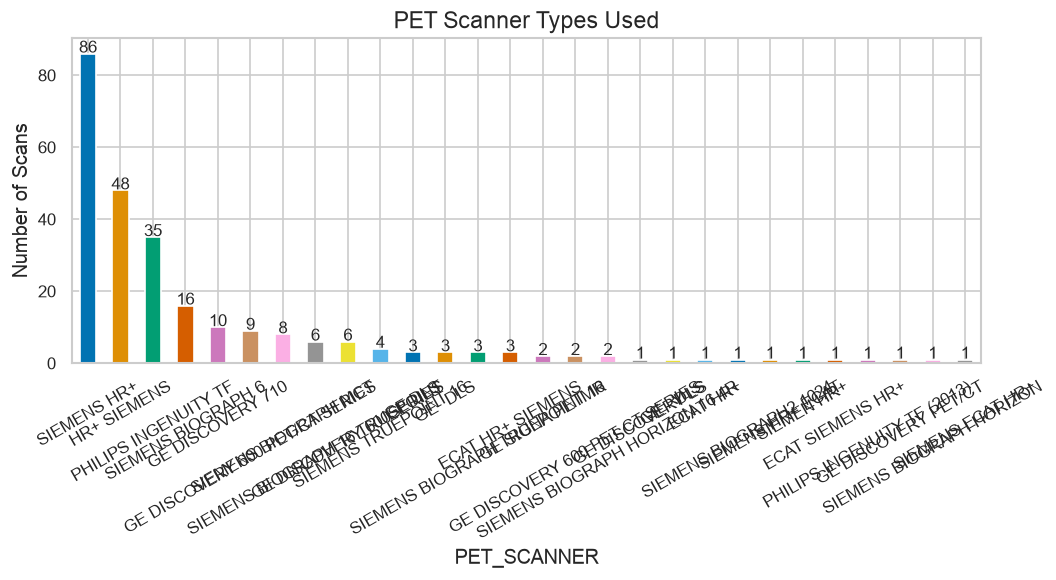

In [4]:
if 'PET_SCANNER' in acq_meta.columns:
    sc = acq_meta['PET_SCANNER'].value_counts()
    fig, ax = plt.subplots(figsize=(9, 5))
    sc.plot(kind='bar', ax=ax, color=sns.color_palette('colorblind', len(sc)), edgecolor='white')
    ax.set_title('PET Scanner Types Used'); ax.set_ylabel('Number of Scans')
    ax.tick_params(axis='x', rotation=30)
    for i, v in enumerate(sc.values):
        ax.text(i, v+0.3, str(v), ha='center', fontsize=10)
    plt.tight_layout(); plt.show()

## 2 · QC Acceptance Rate

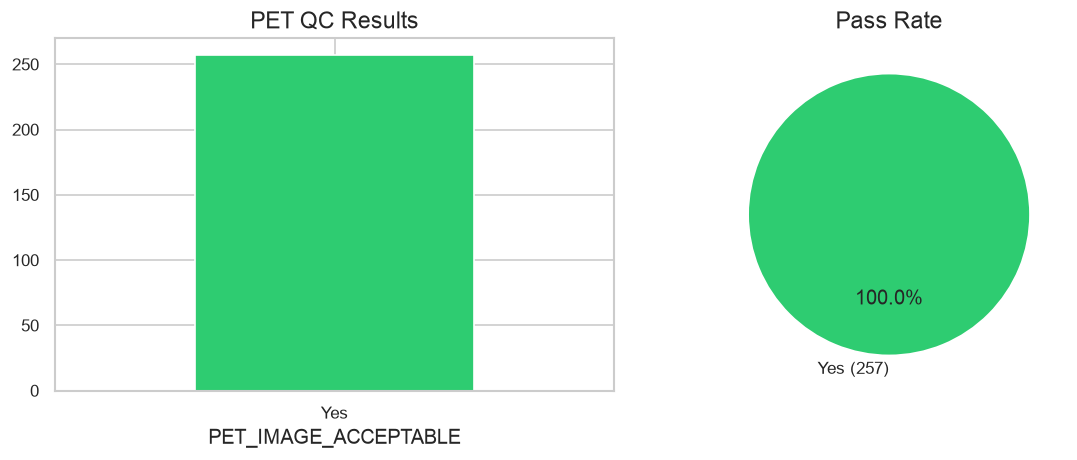

In [5]:
qc_col = 'PET_IMAGE_ACCEPTABLE' if 'PET_IMAGE_ACCEPTABLE' in acq_meta.columns else 'PET_PASS_QC'
if qc_col in acq_meta.columns:
    qc = acq_meta[qc_col].value_counts()
    colors = ['#2ecc71' if 'Yes' in str(k) or k == True else '#e74c3c' for k in qc.index]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    qc.plot(kind='bar', ax=axes[0], color=colors, edgecolor='white')
    axes[0].set_title('PET QC Results'); axes[0].tick_params(axis='x', rotation=0)
    axes[1].pie(qc.values, labels=[f'{k} ({v})' for k,v in qc.items()],
                colors=colors, autopct='%1.1f%%', startangle=90)
    axes[1].set_title('Pass Rate')
    plt.tight_layout(); plt.show()

## 3 · Scan Quality Ratings

Quality rated 1–3: 1=excellent, 2=acceptable, 3=poor.

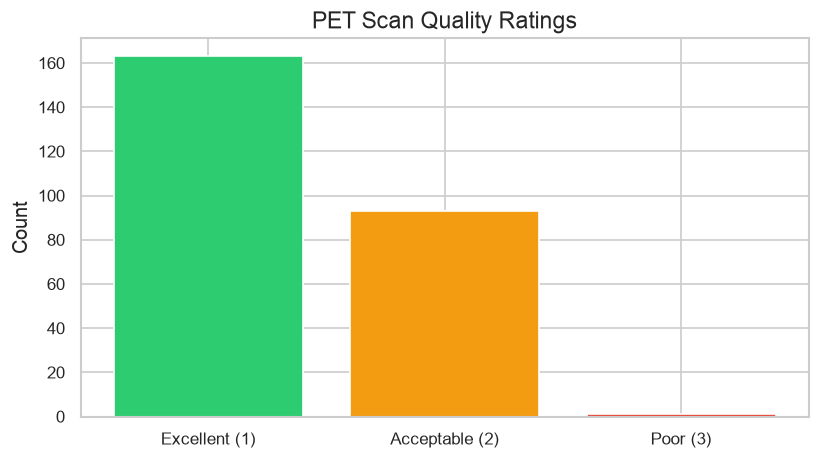

In [6]:
if 'PET_SCAN_QUALITY_RATING' in acq_meta.columns:
    qr = acq_meta['PET_SCAN_QUALITY_RATING'].value_counts().sort_index()
    labels = {1: 'Excellent (1)', 2: 'Acceptable (2)', 3: 'Poor (3)'}
    colors = ['#2ecc71','#f39c12','#e74c3c']
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar([labels.get(k, str(k)) for k in qr.index], qr.values,
           color=colors[:len(qr)], edgecolor='white')
    ax.set_title('PET Scan Quality Ratings'); ax.set_ylabel('Count')
    plt.tight_layout(); plt.show()

## 4 · AV-133 SBR Distributions

Striatal binding ratios by region. Compare to DaTSCAN SBR values — same brain regions, different biological target.

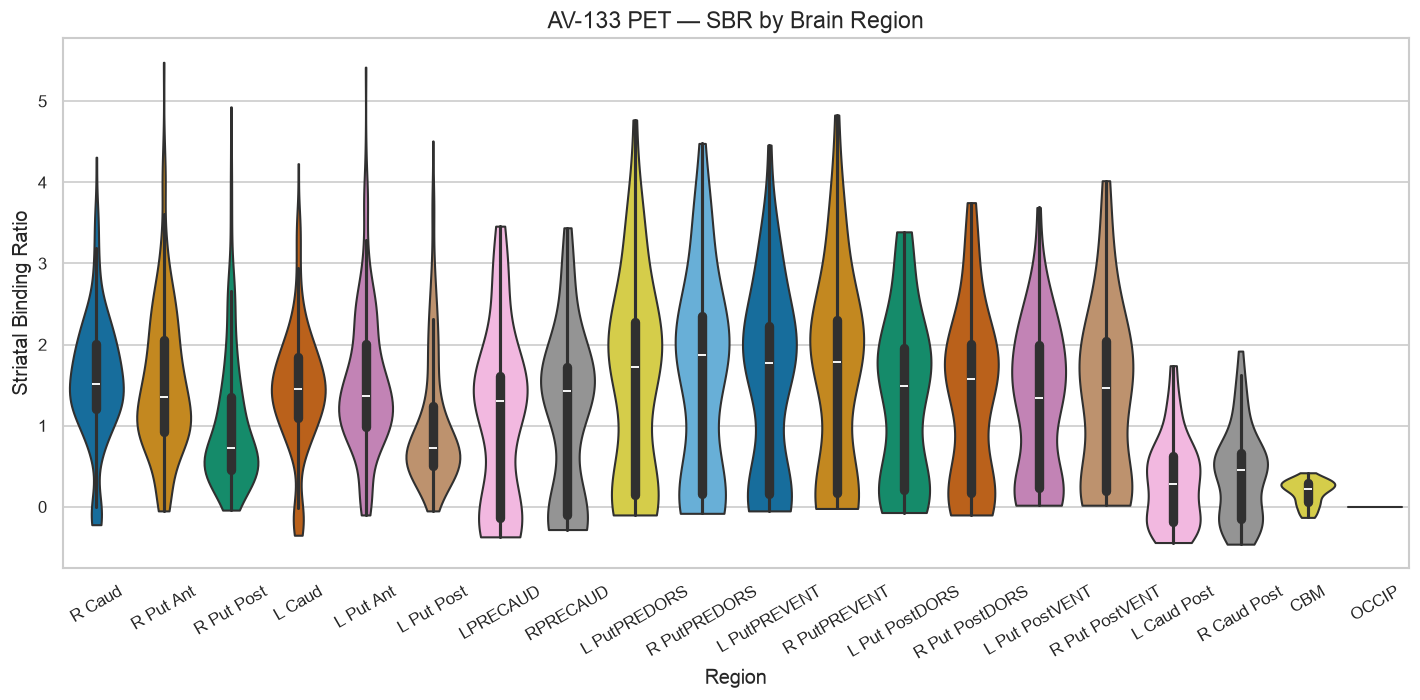

                count   mean    std   min    25%    50%    75%   max
Region                                                              
CBM              54.0  0.181  0.149 -0.13  0.062  0.225  0.298  0.42
L Caud          252.0  1.446  0.759 -0.35  1.090  1.450  1.842  4.23
L Caud Post      54.0  0.317  0.543 -0.44 -0.182  0.280  0.628  1.74
L Put Ant       252.0  1.517  0.868 -0.10  0.990  1.370  2.007  5.42
L Put Post      252.0  1.020  0.809 -0.05  0.500  0.730  1.238  4.51
L Put PostDORS   54.0  1.323  1.052 -0.07  0.202  1.485  1.958  3.39
L Put PostVENT   54.0  1.260  0.945  0.02  0.232  1.340  1.995  3.69
L PutPREDORS     54.0  1.537  1.260 -0.10  0.150  1.720  2.278  4.77
L PutPREVENT     54.0  1.513  1.183 -0.05  0.160  1.770  2.225  4.46
LPRECAUD         54.0  1.070  1.082 -0.37 -0.138  1.300  1.608  3.46
OCCIP            54.0  0.000  0.000  0.00  0.000  0.000  0.000  0.00
R Caud          252.0  1.565  0.771 -0.22  1.200  1.515  2.002  4.31
R Caud Post      54.0  0.392  0.56

In [7]:
sbr_valid = sbr_pet[sbr_pet.get('PET_ANALYZED', pd.Series(['Yes']*len(sbr_pet))) == 'Yes'].copy()             if 'PET_ANALYZED' in sbr_pet.columns else sbr_pet.copy()
sbr_region_cols = {c: c.replace('PET_','').replace('_S','').replace('RPUT','R Put').replace('LPUT','L Put')
                      .replace('RCAUD','R Caud').replace('LCAUD','L Caud')
                      .replace('ANT',' Ant').replace('POST',' Post')
                   for c in sbr_valid.columns if c.startswith('PET_') and
                   sbr_valid[c].dtype in [np.float64, float]}
sbr_region_cols = {k: v for k, v in sbr_region_cols.items() if sbr_valid[k].dropna().shape[0] > 5}

if sbr_region_cols:
    melt = sbr_valid[list(sbr_region_cols.keys())].rename(columns=sbr_region_cols).melt(
        var_name='Region', value_name='SBR').dropna()
    fig, ax = plt.subplots(figsize=(12, 6))
    sns.violinplot(data=melt, x='Region', y='SBR', palette='colorblind', ax=ax,
                   inner='box', cut=0)
    ax.set_title('AV-133 PET — SBR by Brain Region')
    ax.set_ylabel('Striatal Binding Ratio'); ax.tick_params(axis='x', rotation=30)
    plt.tight_layout(); plt.show()
    print(melt.groupby('Region')['SBR'].describe().round(3))

## 5 · Substudy Participant Counts

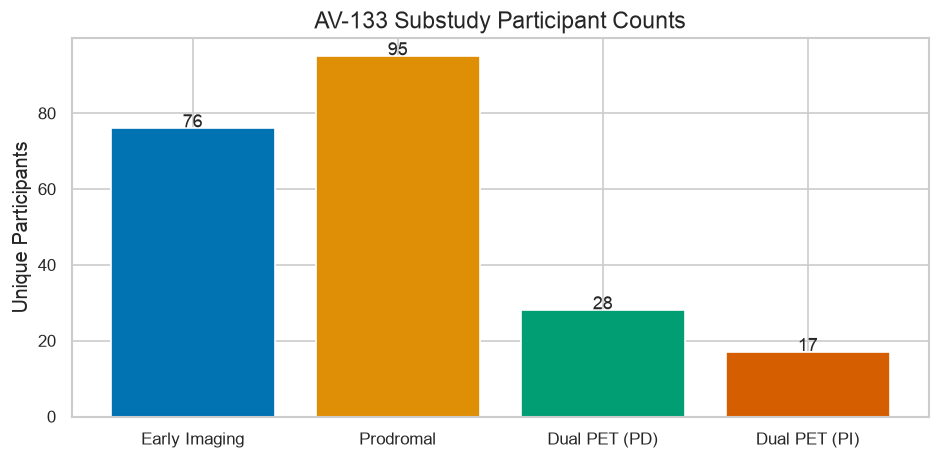

In [8]:
substudies = {
    'Early Imaging': early, 'Prodromal': prodromal,
    'Dual PET (PD)': dual_pd, 'Dual PET (PI)': dual_pi
}
counts = {name: df['PATNO'].nunique() for name, df in substudies.items()}
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(counts.keys(), counts.values(), color=sns.color_palette('colorblind', len(counts)))
ax.set_title('AV-133 Substudy Participant Counts'); ax.set_ylabel('Unique Participants')
for i, (k, v) in enumerate(counts.items()):
    ax.text(i, v+0.3, str(v), ha='center', fontsize=11)
plt.tight_layout(); plt.show()

## 6 · Pre vs Post-Injection Vital Signs

Blood pressure and heart rate are recorded before and after the radiotracer injection as a safety check.

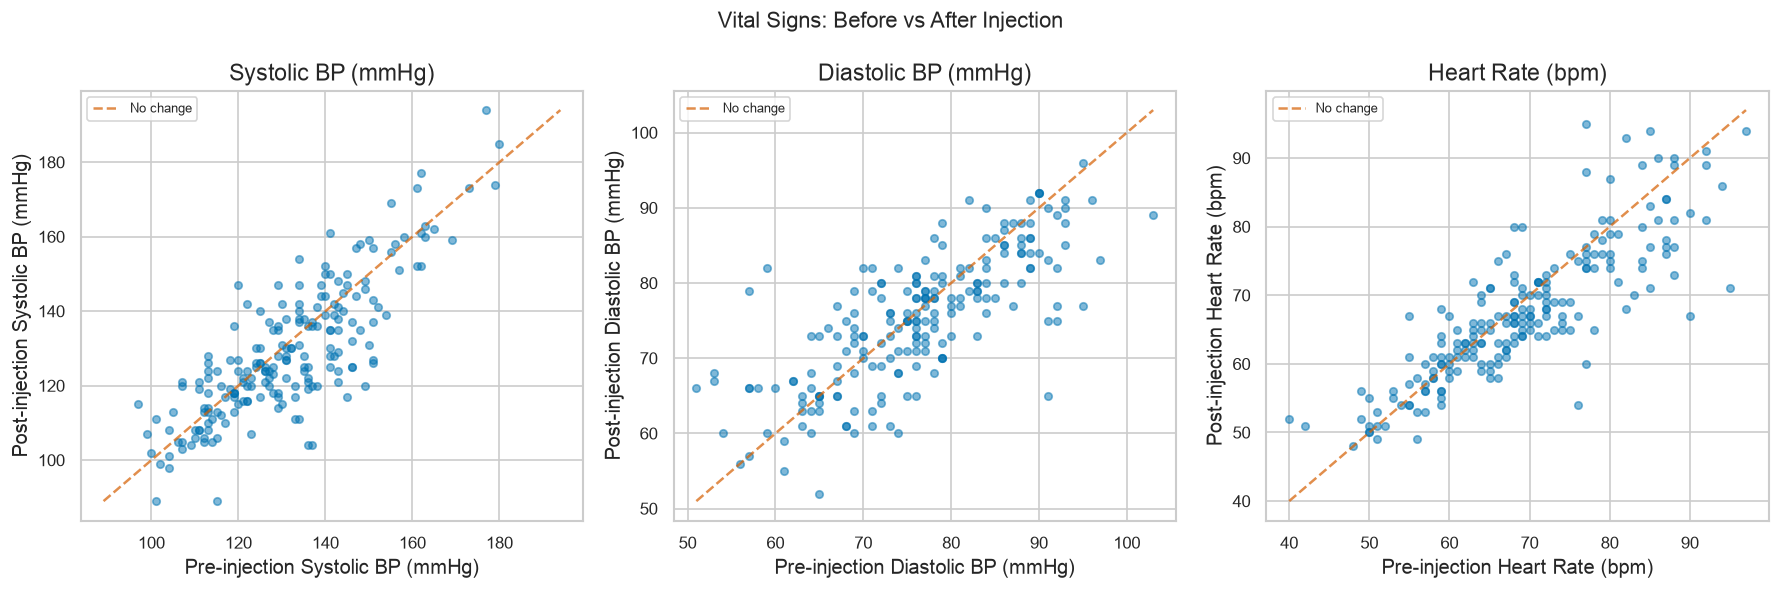

In [9]:
vital_pairs = [('SYSSUPBF','SYSSUPAF','Systolic BP (mmHg)'),
               ('DIASUPBF','DIASUPAF','Diastolic BP (mmHg)'),
               ('HRSUPBF','HRSUPAF','Heart Rate (bpm)')]
vital_pairs = [(a,b,n) for a,b,n in vital_pairs if a in early.columns and b in early.columns]

if vital_pairs:
    fig, axes = plt.subplots(1, len(vital_pairs), figsize=(5*len(vital_pairs), 5))
    if len(vital_pairs) == 1: axes = [axes]
    for ax, (pre, post, name) in zip(axes, vital_pairs):
        sub = early[[pre, post]].dropna()
        ax.scatter(sub[pre], sub[post], alpha=0.5, s=20,
                   color=sns.color_palette('colorblind')[0])
        mn = min(sub.min()); mx = max(sub.max())
        ax.plot([mn,mx],[mn,mx],'r--', alpha=0.7, label='No change')
        ax.set_xlabel(f'Pre-injection {name}'); ax.set_ylabel(f'Post-injection {name}')
        ax.set_title(name); ax.legend(fontsize=8)
    plt.suptitle('Vital Signs: Before vs After Injection', fontsize=13)
    plt.tight_layout(); plt.show()

## Key Takeaways

- **AV-133 measures VMAT2** (dopamine vesicular transporter) — complementary to DaTSCAN's DAT measure
- **Smaller dataset (~257 scans)** than DaTSCAN; collected in specific substudies
- **High image quality** expected given the careful QC process
- **Anterior putamen SBR** is most sensitive — consistent with DaTSCAN findings
- **Vital signs** show only minor changes pre/post injection — tracer is well-tolerated